#**Procesamiento Clasico**
Fuentes usadas:

«OpenCV: Contours : Getting started». https://docs.opencv.org/4.x/d4/d73/tutorial_py_contours_begin.html


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Imagen seleccionada: IMG_6278.JPG


(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

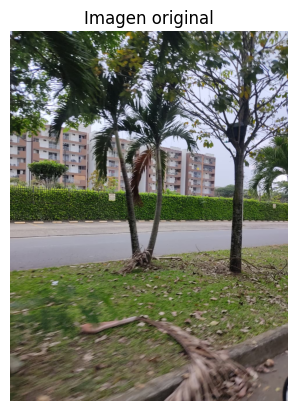

In [ ]:

import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/drive/MyDrive/Dataset_pdi_proyecto/"

#formatos
valid_ext = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")
all_images = [f for f in os.listdir(folder) if f.endswith(valid_ext)]

# elegir una imagen random
random_image = random.choice(all_images)
img_path = os.path.join(folder, random_image)

print("Imagen seleccionada:", random_image)

img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Imagen original")
plt.axis("off")

In [ ]:
img_contours = img_rgb.copy()

(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

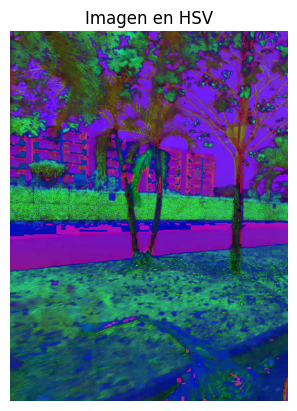

In [ ]:
#Cambios de modo de color
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

plt.imshow(hsv)
plt.title("Imagen en HSV")
plt.axis("off")


In [ ]:
lower_green = np.array([25, 40, 40])
upper_green = np.array([85, 255, 255])

mask_green = cv2.inRange(hsv, lower_green, upper_green)


In [ ]:
# Veg_baja sera mas clara
lower_grass = np.array([30, 60, 80])
upper_grass = np.array([80, 255, 255])
mask_grass = cv2.inRange(hsv, lower_grass, upper_grass)

#Hojas verde oscuro
lower_tree_green = np.array([25, 40, 20])
upper_tree_green = np.array([70, 255, 255])
mask_tree_green = cv2.inRange(hsv, lower_tree_green, upper_tree_green)

#Tronco sera cafe
lower_tree_brown = np.array([5, 50, 20])
upper_tree_brown = np.array([20, 255, 200])
mask_tree_brown = cv2.inRange(hsv, lower_tree_brown, upper_tree_brown)

#Union para mascara de arbol
mask_tree = cv2.bitwise_or(mask_tree_green, mask_tree_brown)

In [ ]:
lower_pav = np.array([0, 0, 120])
upper_pav = np.array([180, 30, 255])

mask_pav = cv2.inRange(hsv, lower_pav, upper_pav)

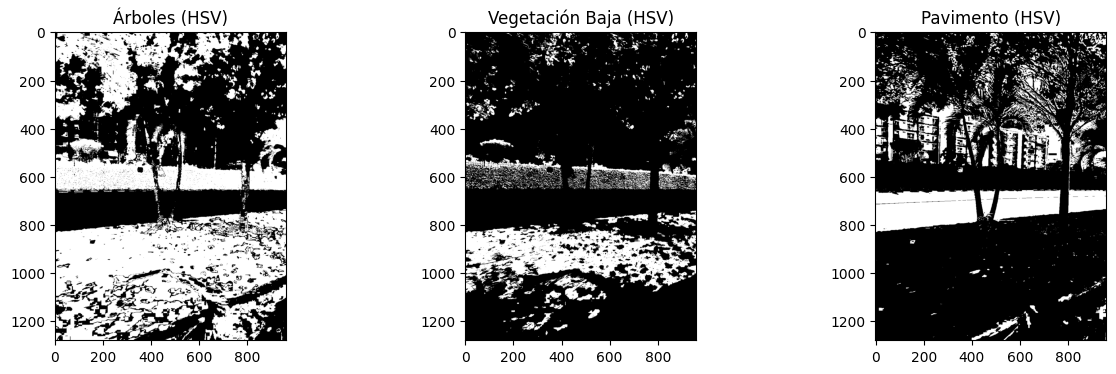

In [ ]:
plt.figure(figsize=(15,4))

plt.subplot(131)
plt.imshow(mask_tree, cmap="gray")
plt.title("Árboles (HSV)")

plt.subplot(132)
plt.imshow(mask_grass, cmap="gray")
plt.title("Vegetación Baja (HSV)")

plt.subplot(133)
plt.imshow(mask_pav, cmap="gray")
plt.title("Pavimento (HSV)")

plt.show()


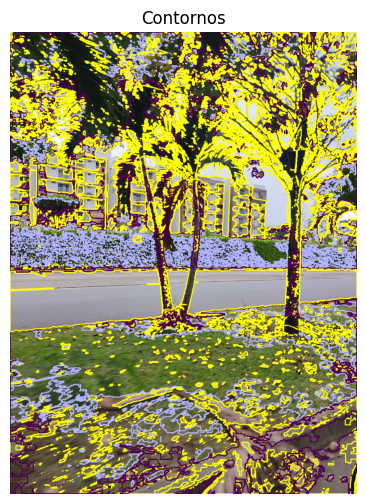

In [ ]:
# Pasto
contours_grass, _ = cv2.findContours(mask_grass, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(img_contours, contours_grass, -1, (180, 180, 255), 2)

# Árboles
contours_tree, _ = cv2.findContours(mask_tree, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(img_contours, contours_tree, -1, (80, 0, 80), 2)

# Pavimento
contours_pav, _ = cv2.findContours(mask_pav, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(img_contours, contours_pav, -1, (255, 255, 0), 2)

plt.figure(figsize=(6,6))
plt.imshow(img_contours)
plt.title("Contornos")
plt.axis("off")
plt.show()

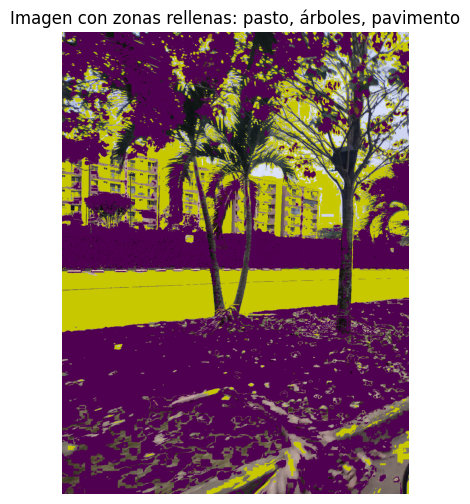

In [ ]:
# Copia
img_filled = img_rgb.copy()
# Rosado claro
color_grass = (255, 0, 255)
# Morado oscuro
color_tree = (80, 0, 80)
# Amarillo
color_pav = (200, 200, 0)

# Rellenar veg_baja
img_filled[mask_grass > 0] = color_grass

# Rellenar veg_alta
img_filled[mask_tree > 0] = color_tree

# Rellenar pavimento
img_filled[mask_pav > 0] = color_pav

plt.figure(figsize=(6,6))
plt.imshow(img_filled)
plt.title("Imagen con zonas rellenas: pasto, árboles, pavimento")
plt.axis("off")
plt.show()


#Implementación de **YOLOv11s**
Fuentes Usadas:

Ultralytics, «Segment», 16 de noviembre de 2025. https://docs.ultralytics.com/es/tasks/segment/#models

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.4 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/datasets

Mounted at /content/drive


In [20]:
#Copiamos el dataset a usar
!cp "/content/drive/MyDrive/Try_yolo/DatasetV6.zip" "/content/"

In [21]:
!unzip "/content/DatasetV5.zip" -d /content/datasets/

Archive:  /content/DatasetV5.zip
replace /content/datasets/README.dataset.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: /content/datasets/README.dataset.txt  
  inflating: /content/datasets/README.roboflow.txt  
  inflating: /content/datasets/data.yaml  
 extracting: /content/datasets/test/images/1000305481_jpg.rf.22ee3197109a14e6b6f793db41171313.jpg  
 extracting: /content/datasets/test/images/IMG_6050_jpg.rf.6d50f8df366307a5d0407c8525f95b7d.jpg  
 extracting: /content/datasets/test/images/IMG_6053_jpg.rf.6e727fc7960b9c67dc52cd117a87aba2.jpg  
 extracting: /content/datasets/test/images/IMG_6067_jpg.rf.82c229f7981c1385ba3b06042796be20.jpg  
 extracting: /content/datasets/test/images/IMG_6105_jpg.rf.dc28ff27fd0f10f630b3e718a71a50ed.jpg  
 extracting: /content/datasets/test/images/IMG_6274_JPG.rf.a3944375d55910e681e967f6a0bd3371.jpg  
 extracting: /content/datasets/test/images/IMG_6280_JPG.rf.d7e7d064f273454219fd327c32423a9c.jpg  
 extracting: /content/datasets/test/images/IM

In [22]:
from ultralytics import YOLO
# Cargaremos el modelo de yolov11 a usar
model = YOLO('yolo11s-seg.pt')
#Entrenamiento del modelo
results = model.train(
    data="/content/datasets/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    plots=True
)


Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train6, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pos

In [23]:
#Seleccionamos el mejor modelo
model = YOLO('/content/runs/segment/train5/weights/best.pt')
#Obtenemos las metricas arrojadas y alojadas en Val
metrics = model.val()
print(metrics)

Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,977 parameters, 0 gradients, 32.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2056.5±293.1 MB/s, size: 112.4 KB)
val: Scanning /content/datasets/valid/labels.cache... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 47.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.8s
                   all         23        171      0.796      0.427      0.532      0.386      0.675      0.411      0.484      0.325
              paviment         21         57      0.838      0.455      0.573      0.438      0.706      0.421       0.49      0.346
              veg_alta         20         71      0.681      0.361      0.418       0.28      0.508      0.324      0.365      0.171
              veg_baja         22         43 

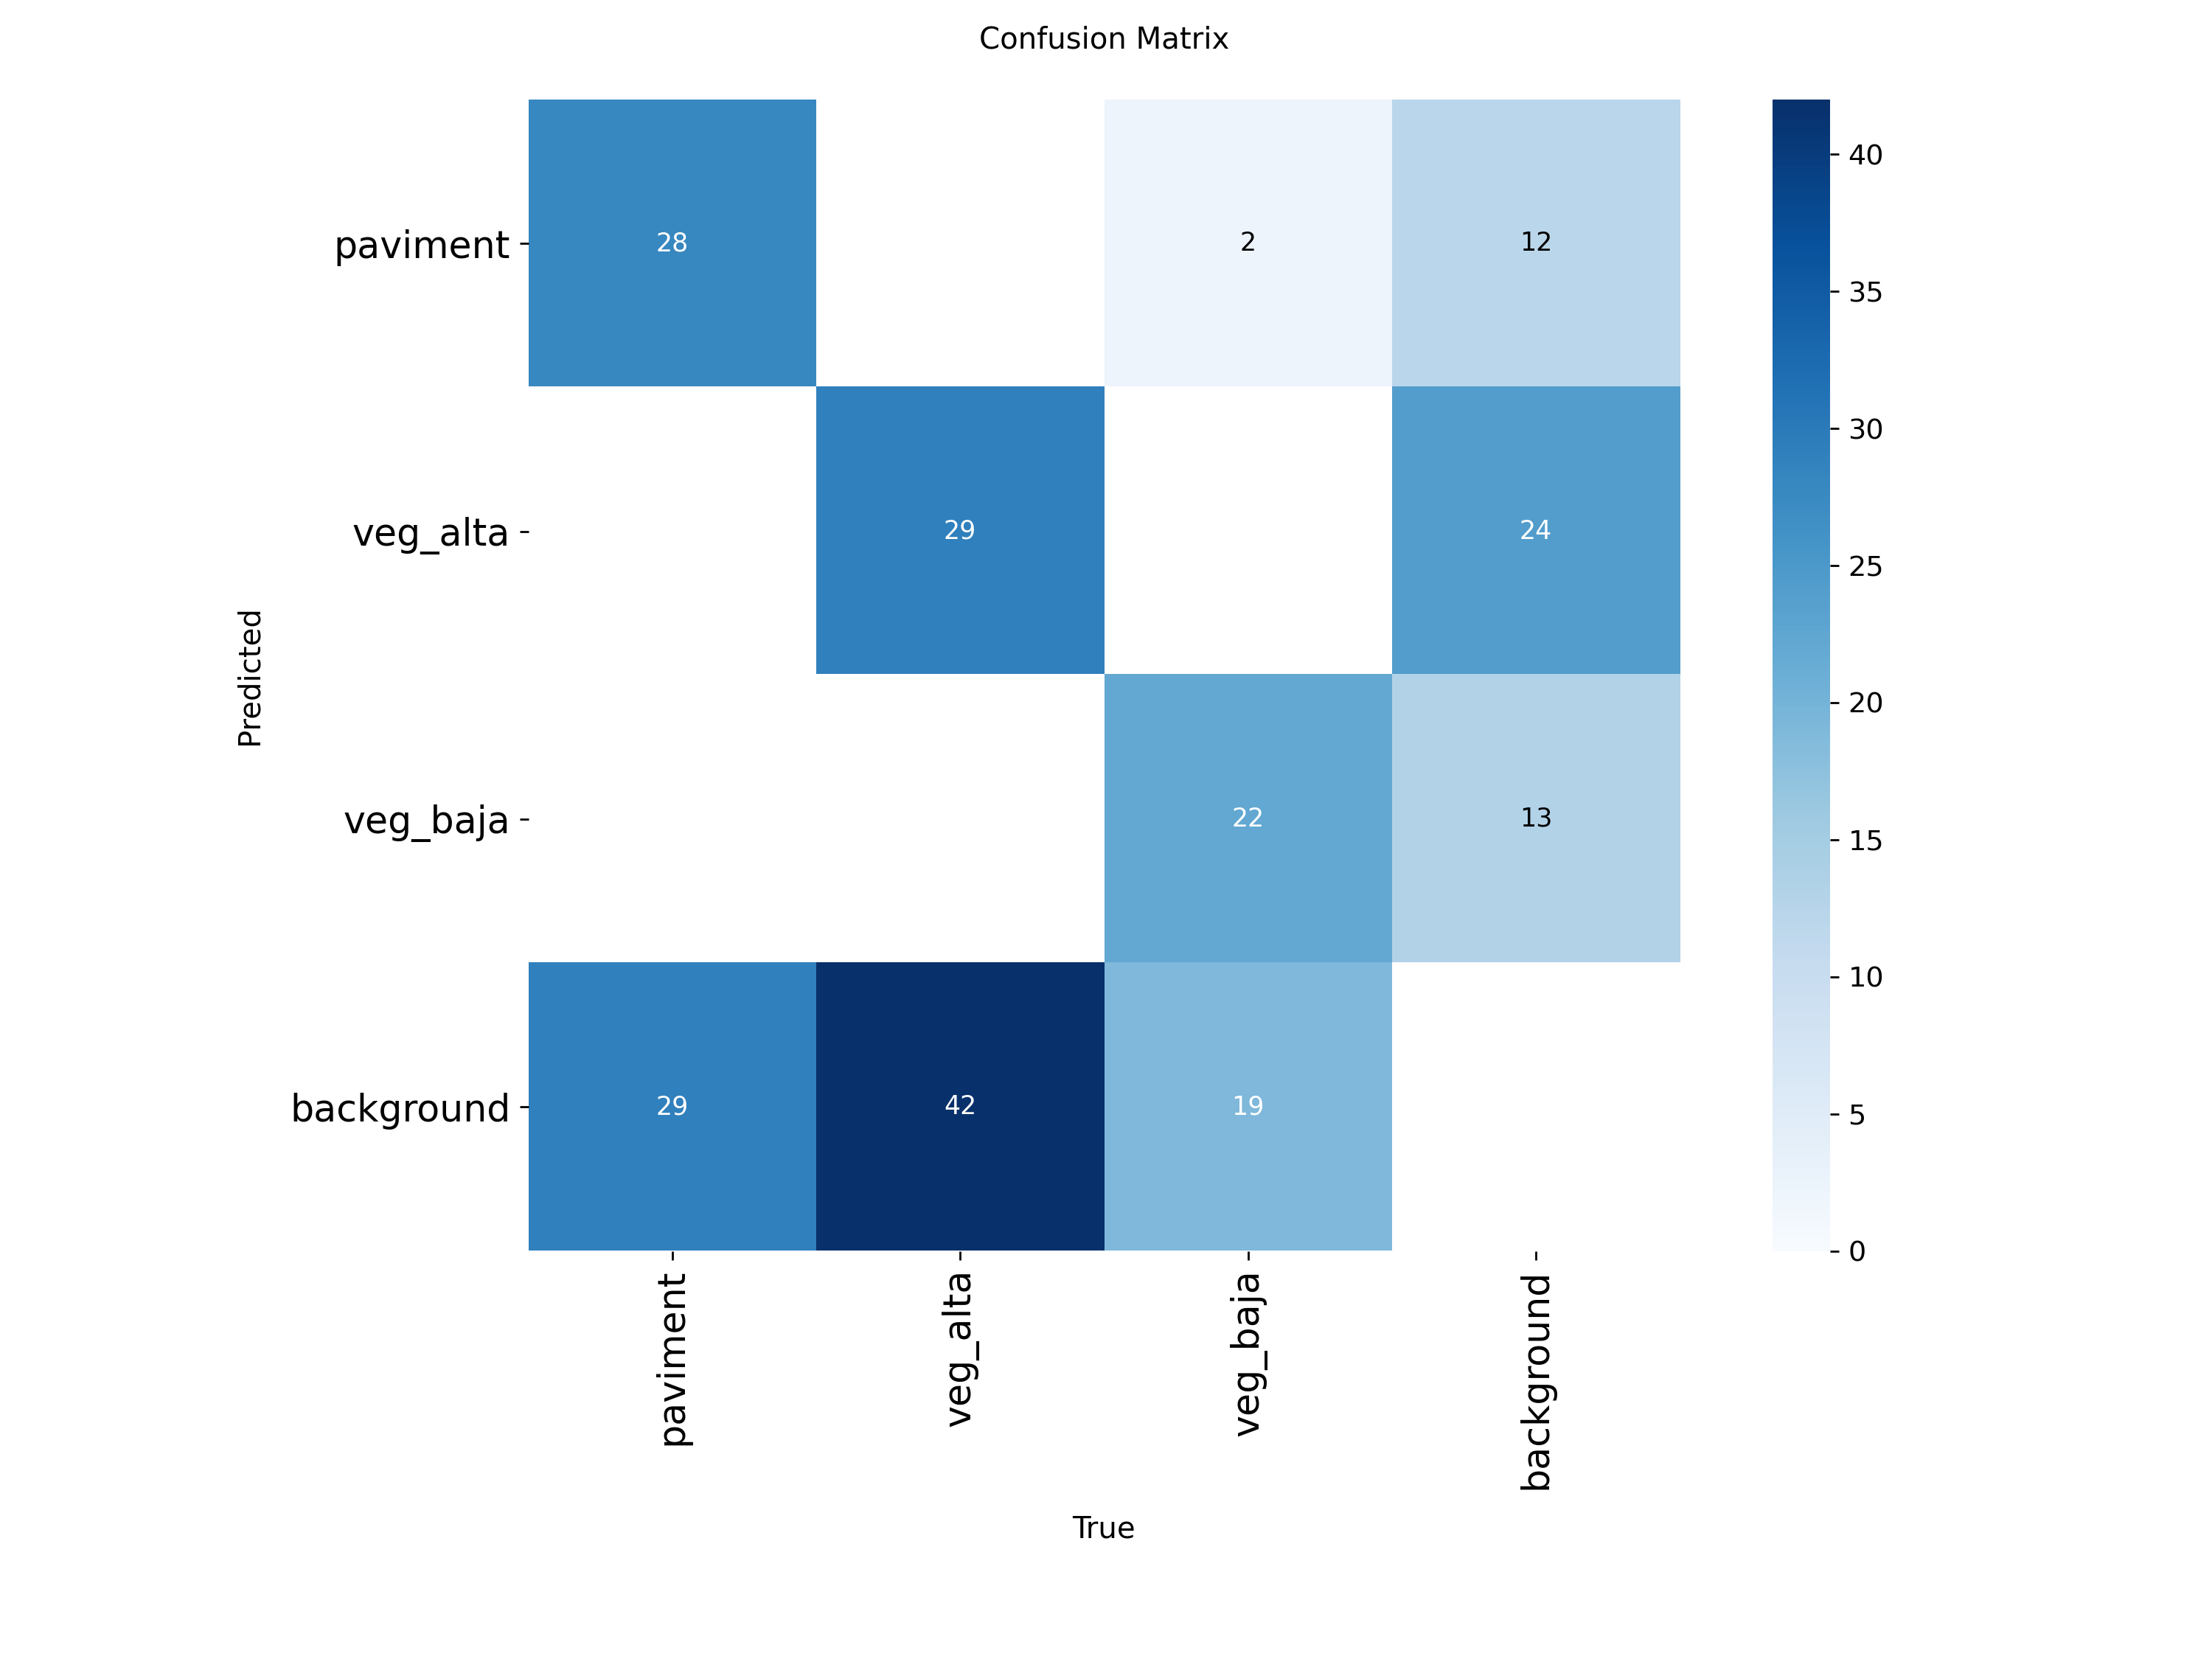

In [24]:
from IPython.display import Image, display

display(Image(filename='runs/segment/train5/confusion_matrix.png'))
#Matriz de Confusion

In [25]:
#Metricas printeadas para mejor visualización
m = metrics.results_dict

print("\nMetricas de cajas")
print(f"Precision B: {m['metrics/precision(B)']:.3f}")
print(f"Recall B: {m['metrics/recall(B)']:.3f}")
print(f"mAP50 B: {m['metrics/mAP50(B)']:.3f}")
print(f"mAP50_95 B: {m['metrics/mAP50-95(B)']:.3f}")

print("\nMetricas de segmentacion")
print(f"Precision M: {m['metrics/precision(M)']:.3f}")
print(f"Recall M: {m['metrics/recall(M)']:.3f}")
print(f"mAP50 M: {m['metrics/mAP50(M)']:.3f}")
print(f"mAP50_95 M: {m['metrics/mAP50-95(M)']:.3f}")



Metricas de cajas
Precision B: 0.796
Recall B: 0.427
mAP50 B: 0.532
mAP50_95 B: 0.386

Metricas de segmentacion
Precision M: 0.675
Recall M: 0.411
mAP50 M: 0.484
mAP50_95 M: 0.325



image 1/12 /content/datasets/test/images/1000305481_jpg.rf.22ee3197109a14e6b6f793db41171313.jpg: 640x640 1 veg_alta, 2 veg_bajas, 20.2ms
image 2/12 /content/datasets/test/images/IMG_6050_jpg.rf.6d50f8df366307a5d0407c8525f95b7d.jpg: 640x640 3 paviments, 2 veg_altas, 1 veg_baja, 20.3ms
image 3/12 /content/datasets/test/images/IMG_6053_jpg.rf.6e727fc7960b9c67dc52cd117a87aba2.jpg: 640x640 3 paviments, 4 veg_altas, 3 veg_bajas, 20.3ms
image 4/12 /content/datasets/test/images/IMG_6067_jpg.rf.82c229f7981c1385ba3b06042796be20.jpg: 640x640 1 paviment, 1 veg_alta, 2 veg_bajas, 19.7ms
image 5/12 /content/datasets/test/images/IMG_6105_jpg.rf.dc28ff27fd0f10f630b3e718a71a50ed.jpg: 640x640 2 paviments, 1 veg_alta, 1 veg_baja, 38.4ms
image 6/12 /content/datasets/test/images/IMG_6274_JPG.rf.a3944375d55910e681e967f6a0bd3371.jpg: 640x640 2 paviments, 2 veg_altas, 2 veg_bajas, 21.2ms
image 7/12 /content/datasets/test/images/IMG_6280_JPG.rf.d7e7d064f273454219fd327c32423a9c.jpg: 640x640 2 paviments, 4 veg_

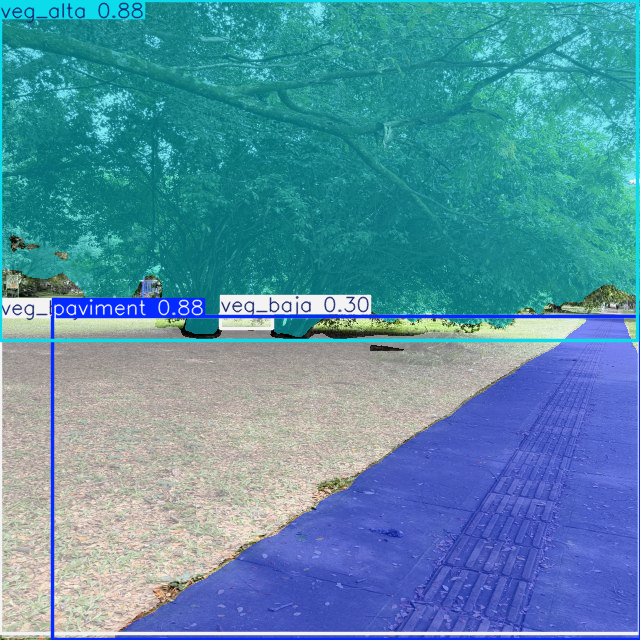

In [26]:
#Mostramos alguna imagen del test para comprobar como se estan haciendo las mascaras
preds = model('/content/datasets/test/images')
preds[3].show()

#Codigo usado para el despliegue(Solo Funciona en Local)
Este es el codigo usado dentro del entorno de ejecución local pero se adjunta aqui como soporte, además el proyecto con la aplicación para el despliegue se adjunta en la entrega tambien.

Fuentes Usadas:

Ultralytics, «Segment», 16 de noviembre de 2025. https://docs.ultralytics.com/es/tasks/segment/#models

Nicolai Nielsen, «Real-time Instance Segmentation with YOLOv8: Create Custom Object Detection Models with Webcam», YouTube. 16 de enero de 2023. [En línea]. Disponible en: https://www.youtube.com/watch?v=4iRFGjNtzNo

In [ ]:
from ultralytics import YOLO
import cv2
import numpy as np

#Cargamos el modelo
model = YOLO("best.pt")
video = r"C:/Users/nicol/Downloads/VIDEO DE PRUEBA.mp4"

#Clases
ID_PAVIMENTO   = 0
ID_VEG_ALTA    = 1
ID_VEG_BAJA    = 2

#Definición parametros para la predicción
for res in model.predict(source=video, stream=True, show=False, conf=0.5):
#for res in model.predict(source=0, stream=True, show=False, conf=0.5):

    frame = res.orig_img.copy()
    h, w = frame.shape[:2]
    total_pixels = h * w

    area_pav = 0
    area_veg_alta = 0
    area_veg_baja = 0

    if res.masks is not None:
        masks = res.masks.data.cpu().numpy()
        classes = res.boxes.cls.cpu().numpy().astype(int)

        for mask, cls in zip(masks, classes):
            pixels = mask.sum()

            if cls == ID_PAVIMENTO:
                area_pav += pixels
            elif cls == ID_VEG_ALTA:
                area_veg_alta += pixels
            elif cls == ID_VEG_BAJA:
                area_veg_baja += pixels

    # 5. Porcentajes de cada mascara por clase
    pct_pav = 100 * area_pav / total_pixels
    pct_veg_alta = 100 * area_veg_alta / total_pixels
    pct_veg_baja = 100 * area_veg_baja / total_pixels

    # Calculo para el Indice de Sombra
    sombra_index = 100 * area_veg_alta / (area_veg_alta + area_pav + 1e-6)

    # Calculo para el Indice de Calor Urbano
    # Formula usadaICU = pavimento / (veg_alta + 1)
    ICU = area_pav / (area_veg_alta + 1)
    #Normalizacion de 0 a 1
    ICU_norm = min(ICU / 10, 1.0)
    ICU_pct = ICU_norm * 100

    # Visualizar en pantalla
    vis = res.plot()

    cv2.putText(vis, f"Veg Alta: {pct_veg_alta:.1f}%", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 2)
    cv2.putText(vis, f"Veg Baja: {pct_veg_baja:.1f}%", (10, 55),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 2)
    cv2.putText(vis, f"Pavimento: {pct_pav:.1f}%", (10, 85),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 2)
    cv2.putText(vis, f"Indice de Sombra: {sombra_index:.1f}%", (10, 115),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 2)

    #Indice de calor urbano mostrar
    cv2.putText(vis, f"ICU (Indice de Calor Urbano): {ICU_pct:.1f}%", (10, 145),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,200,255), 2)

    cv2.imshow("Analisis de Microclima - Segmentacion", vis)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cv2.destroyAllWindows()
